In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set publication style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Load CSV
df = pd.read_csv('Clean_Data.csv')

# 2. Clean numeric columns (strip commas, whitespace, convert to numeric)
numeric_cols = ['Exports_TIV', 'Imports_TIV', 'Net_Trade_TIV', 'Total_Volume_TIV']
for col in numeric_cols:
    if df[col].dtype == object:
        df[col] = df[col].astype(str).str.replace(',', '').str.strip()
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# 3. Filter sovereign nations (exclude regional macro aggregates)
df_sovereign = df[df['Region'] != 'Regional Aggregate'].copy()

print(f"Total dataset records: {len(df)}")
print(f"Sovereign state records: {len(df_sovereign)}")
df_sovereign.head()

Total dataset records: 3985
Sovereign state records: 2973


,Country_Name,Country_Code,Year,Exports_TIV,Imports_TIV,Region,Income_Group,Net_Trade_TIV,Total_Volume_TIV
1,Albania,ALB,2024,0,38000000,Europe & Central Asia,Upper middle income,-38000000,38000000
2,Algeria,DZA,2024,0,205000000,Middle East & North Africa,Upper middle income,-205000000,205000000
3,Angola,AGO,2024,0,16000000,Sub-Saharan Africa,Lower middle income,-16000000,16000000
5,Argentina,ARG,2024,0,45000000,Latin America & Caribbean,Upper middle income,-45000000,45000000
6,Armenia,ARM,2024,0,32000000,Europe & Central Asia,Upper middle income,-32000000,32000000


/tmp/ipykernel_516/1132783175.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(data=top_exporters, x='Exports_Billions', y='Country_Name', palette=palette)


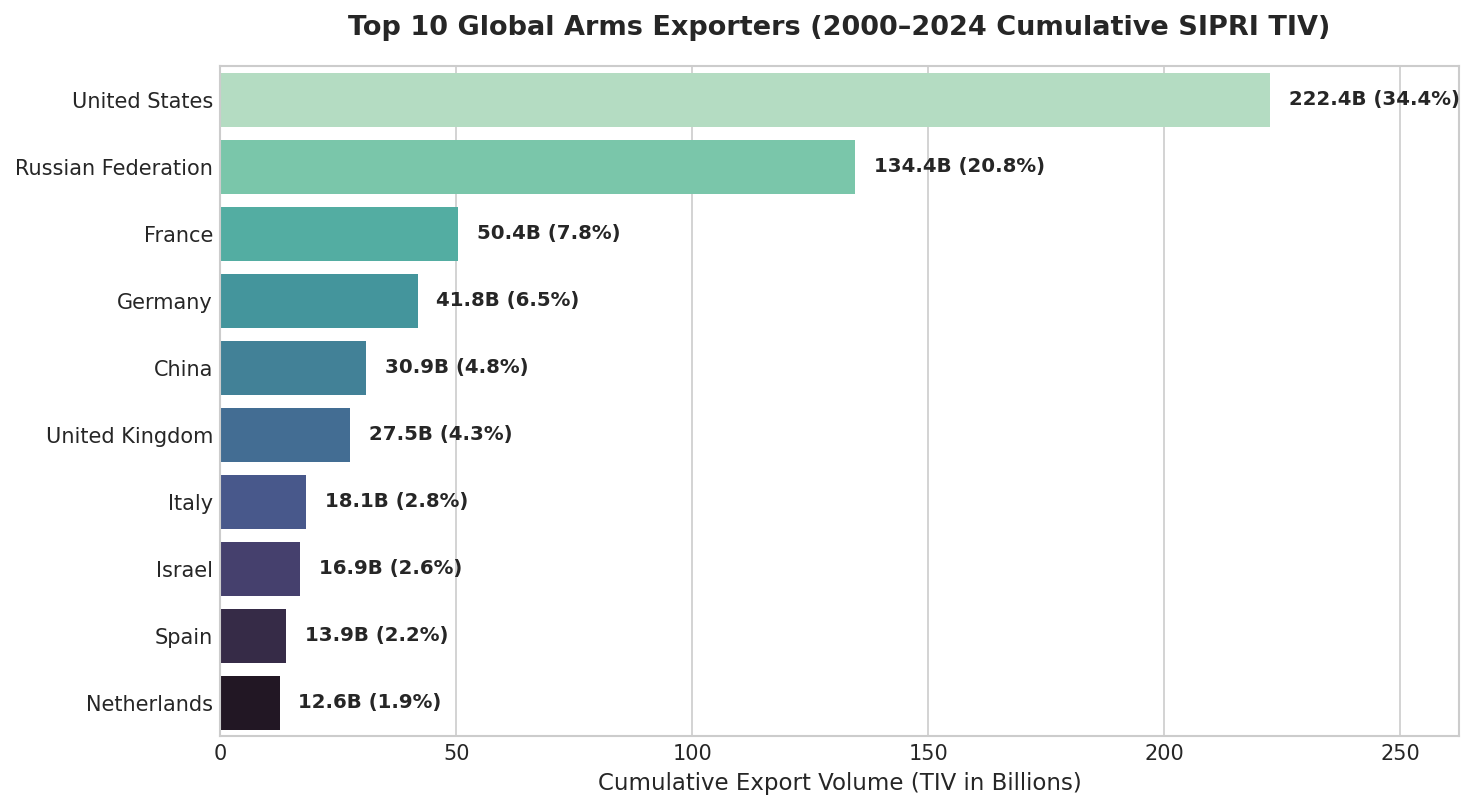

In [2]:
# Aggregate cumulative exports
top_exporters = (
    df_sovereign.groupby('Country_Name')['Exports_TIV']
    .sum()
    .reset_index()
    .sort_values(by='Exports_TIV', ascending=False)
    .head(10)
)

total_global_exports = df_sovereign['Exports_TIV'].sum()
top_exporters['Market_Share_Pct'] = (top_exporters['Exports_TIV'] / total_global_exports) * 100
top_exporters['Exports_Billions'] = top_exporters['Exports_TIV'] / 1e9

# Plot
plt.figure(figsize=(10, 5.5))
palette = sns.color_palette("mako_r", len(top_exporters))
barplot = sns.barplot(data=top_exporters, x='Exports_Billions', y='Country_Name', palette=palette)

plt.title('Top 10 Global Arms Exporters (2000–2024 Cumulative SIPRI TIV)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Cumulative Export Volume (TIV in Billions)', fontsize=11)
plt.ylabel('')

# Annotate bars with values and market share percentages
for p, (_, row) in zip(barplot.patches, top_exporters.iterrows()):
    width = p.get_width()
    barplot.annotate(f"{width:.1f}B ({row['Market_Share_Pct']:.1f}%)",
                     (width + 4, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=9.5, weight='semibold')

plt.xlim(0, top_exporters['Exports_Billions'].max() * 1.18)
plt.tight_layout()
plt.savefig('01_top_exporters_market_share.png', bbox_inches='tight')
plt.show()

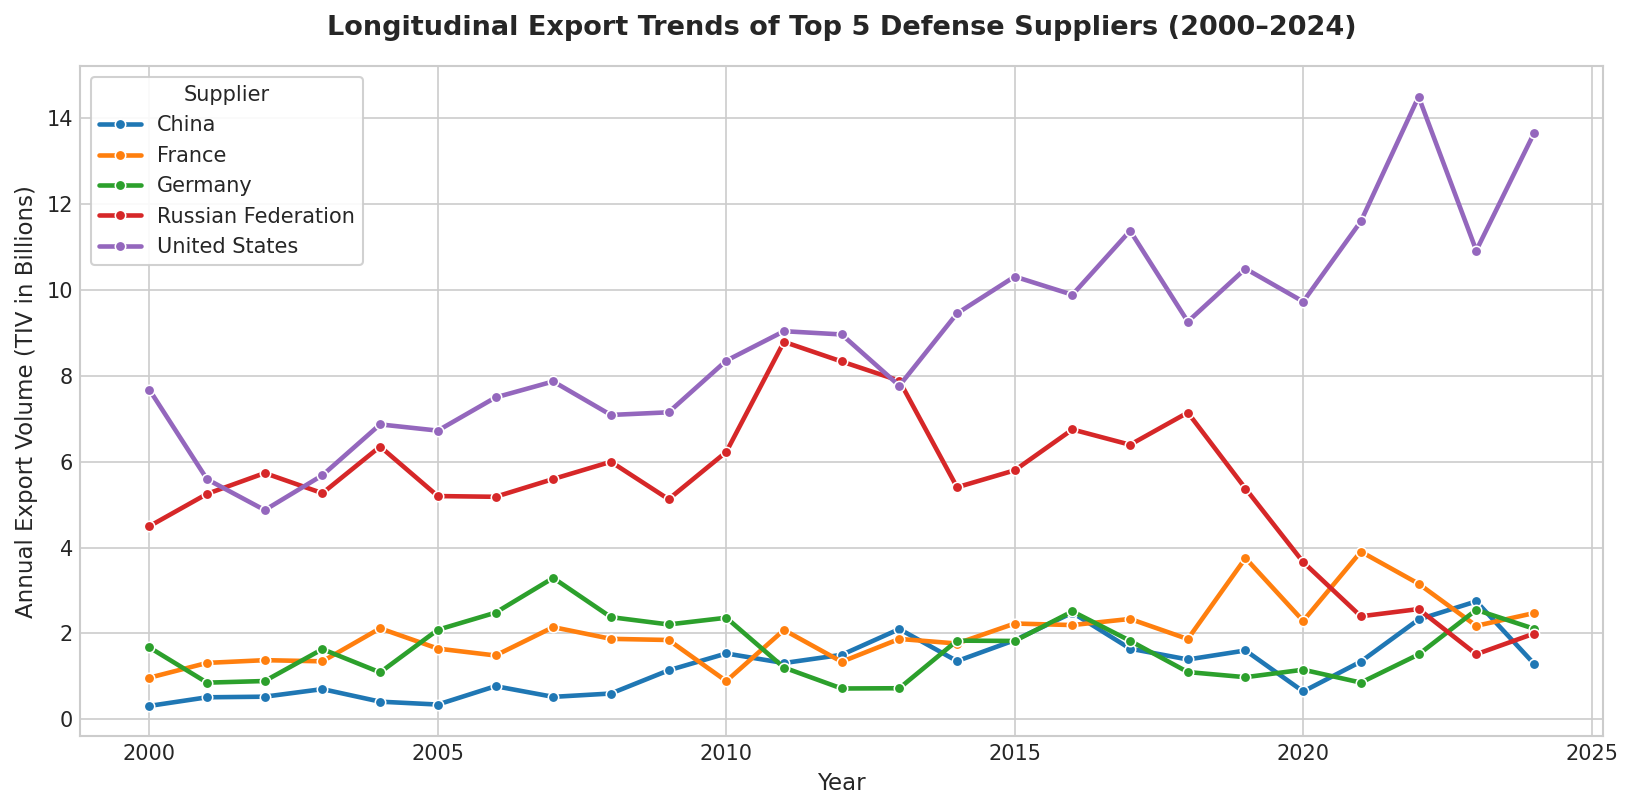

In [3]:
# Select top 5 exporters for timeline analysis
top_5_countries = top_exporters['Country_Name'].head(5).tolist()
df_top5 = df_sovereign[df_sovereign['Country_Name'].isin(top_5_countries)].copy()
df_top5['Exports_Billions'] = df_top5['Exports_TIV'] / 1e9

plt.figure(figsize=(11, 5.5))
sns.lineplot(
    data=df_top5,
    x='Year',
    y='Exports_Billions',
    hue='Country_Name',
    marker='o',
    markersize=5,
    linewidth=2.2
)

plt.title('Longitudinal Export Trends of Top 5 Defense Suppliers (2000–2024)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Year', fontsize=11)
plt.ylabel('Annual Export Volume (TIV in Billions)', fontsize=11)
plt.legend(title='Supplier', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('02_top5_longitudinal_trajectory.png', bbox_inches='tight')
plt.show()

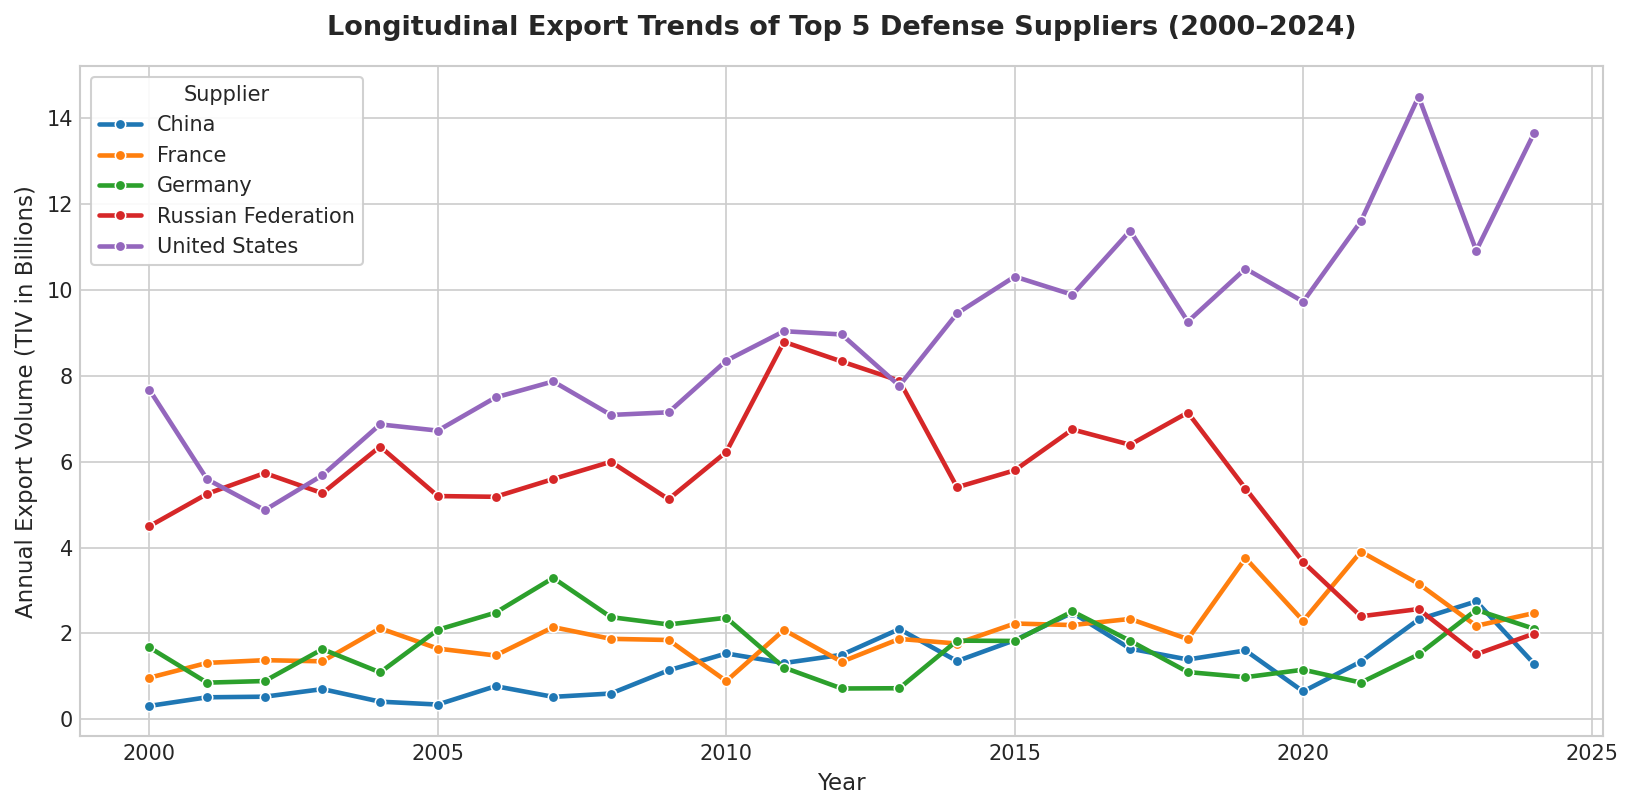

In [4]:
# Select top 5 exporters for timeline analysis
top_5_countries = top_exporters['Country_Name'].head(5).tolist()
df_top5 = df_sovereign[df_sovereign['Country_Name'].isin(top_5_countries)].copy()
df_top5['Exports_Billions'] = df_top5['Exports_TIV'] / 1e9

plt.figure(figsize=(11, 5.5))
sns.lineplot(
    data=df_top5,
    x='Year',
    y='Exports_Billions',
    hue='Country_Name',
    marker='o',
    markersize=5,
    linewidth=2.2
)

plt.title('Longitudinal Export Trends of Top 5 Defense Suppliers (2000–2024)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Year', fontsize=11)
plt.ylabel('Annual Export Volume (TIV in Billions)', fontsize=11)
plt.legend(title='Supplier', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('02_top5_longitudinal_trajectory.png', bbox_inches='tight')
plt.show()

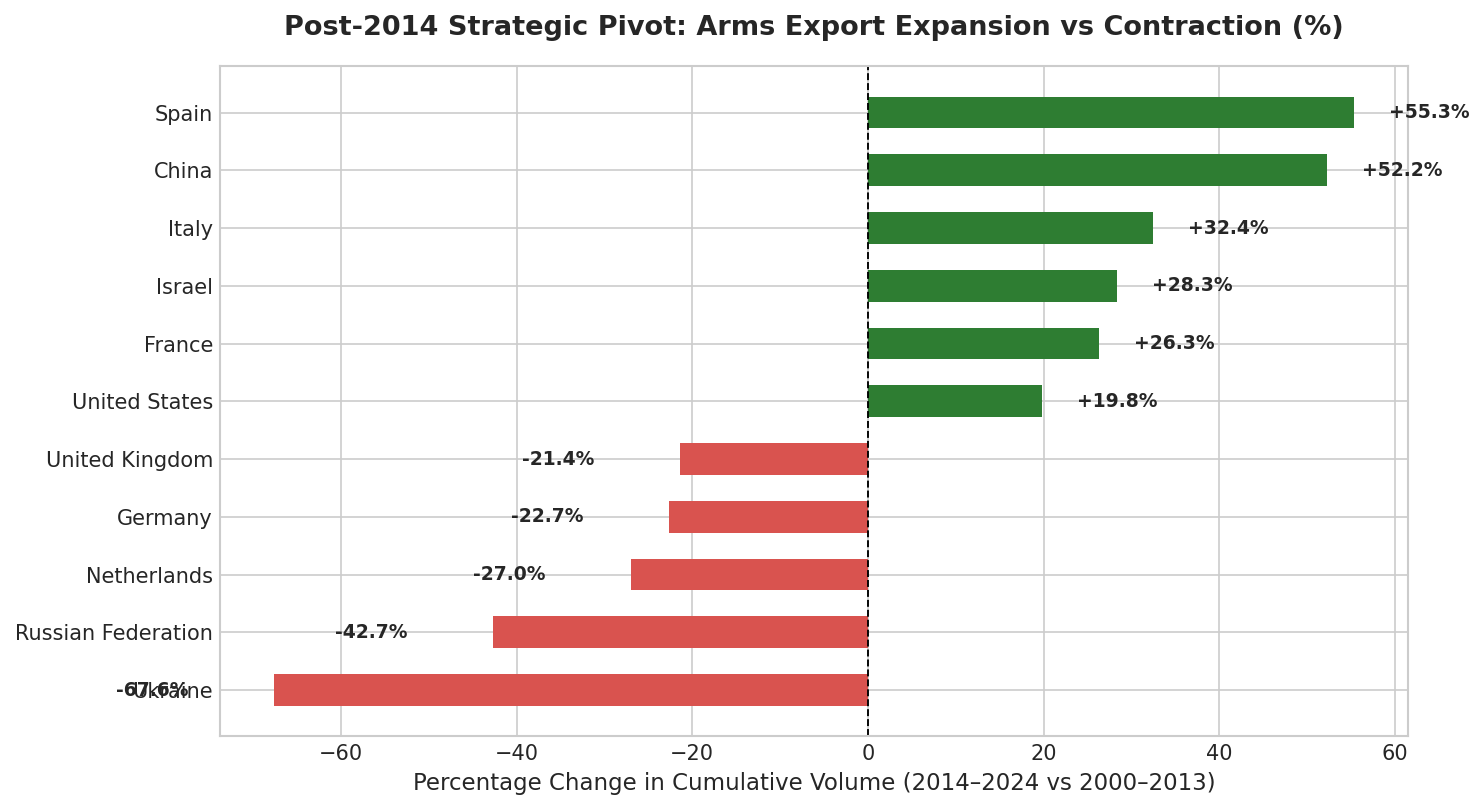

In [5]:
# Partition into strategic geopolitical eras
df_sovereign['Era'] = np.where(df_sovereign['Year'] <= 2013, '2000–2013', '2014–2024')

era_pivot = df_sovereign.pivot_table(
    index='Country_Name',
    columns='Era',
    values='Exports_TIV',
    aggfunc='sum'
).fillna(0)

era_pivot['Total'] = era_pivot['2000–2013'] + era_pivot['2014–2024']

# Filter major exporters (>10B TIV cumulative)
major_pivot = era_pivot[era_pivot['Total'] > 1e10].copy()
major_pivot['Growth_Pct'] = ((major_pivot['2014–2024'] - major_pivot['2000–2013']) / major_pivot['2000–2013']) * 100
major_pivot = major_pivot.sort_values(by='Growth_Pct', ascending=True)

# Divergence plot
plt.figure(figsize=(10, 5.5))
bar_colors = ['#d9534f' if val < 0 else '#2e7d32' for val in major_pivot['Growth_Pct']]
plt.barh(major_pivot.index, major_pivot['Growth_Pct'], color=bar_colors, height=0.55)
plt.axvline(0, color='black', linewidth=0.9, linestyle='--')

plt.title('Post-2014 Strategic Pivot: Arms Export Expansion vs Contraction (%)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Percentage Change in Cumulative Volume (2014–2024 vs 2000–2013)', fontsize=11)
plt.ylabel('')

for i, (idx, val) in enumerate(zip(major_pivot.index, major_pivot['Growth_Pct'])):
    x_pos = val + (4 if val >= 0 else -18)
    plt.text(x_pos, i, f"{val:+.1f}%", va='center', fontsize=9, weight='bold')

plt.tight_layout()
plt.savefig('03_post2014_pivot_growth.png', bbox_inches='tight')
plt.show()

/tmp/ipykernel_516/3698741603.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(data=top_importers, x='Imports_Billions', y='Country_Name', palette=palette)


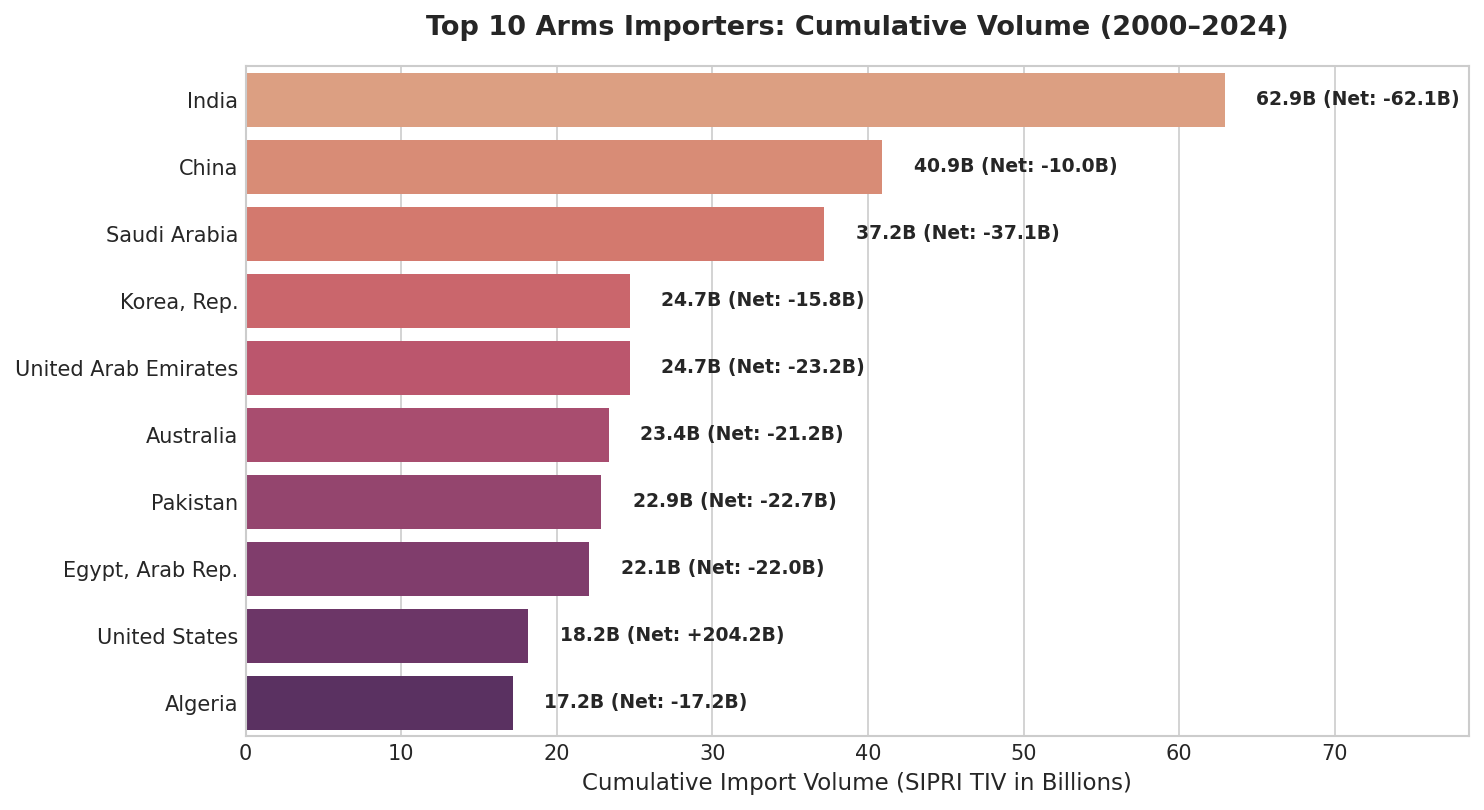

In [6]:
# Aggregate Top 10 Importers and their trade posture
top_importers = (
    df_sovereign.groupby('Country_Name')
    .agg({'Imports_TIV': 'sum', 'Exports_TIV': 'sum', 'Net_Trade_TIV': 'sum'})
    .sort_values(by='Imports_TIV', ascending=False)
    .head(10)
    .reset_index()
)

# Convert to Billions
top_importers['Imports_Billions'] = top_importers['Imports_TIV'] / 1e9
top_importers['Net_Billions'] = top_importers['Net_Trade_TIV'] / 1e9

plt.figure(figsize=(10, 5.5))
palette = sns.color_palette("flare", len(top_importers))
barplot = sns.barplot(data=top_importers, x='Imports_Billions', y='Country_Name', palette=palette)

plt.title('Top 10 Arms Importers: Cumulative Volume (2000–2024)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Cumulative Import Volume (SIPRI TIV in Billions)', fontsize=11)
plt.ylabel('')

for p, (_, row) in zip(barplot.patches, top_importers.iterrows()):
    width = p.get_width()
    net_val = row['Net_Billions']
    barplot.annotate(f"{width:.1f}B (Net: {net_val:+.1f}B)",
                     (width + 2, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=9, weight='semibold')

plt.xlim(0, top_importers['Imports_Billions'].max() * 1.25)
plt.tight_layout()
plt.savefig('04_top10_importers_balance.png', bbox_inches='tight')
plt.show()